# 04.1 — CNNs and Transfer Learning

How convolutional networks see images, a small CNN that beats the MLP from 02.2, data augmentation,
the classic architectures, and transfer learning with a pretrained ResNet.

## What's in this notebook

- 1\. Why convolutions for images
- 2\. How a convolution works
- 3\. Pooling, receptive field and 1×1 convolutions
- 4\. A small CNN on FashionMNIST
- 5\. What the first layer sees
- 6\. Data augmentation
- 7\. Classic architectures
- 8\. Transfer learning
- 9\. Trade-offs
- 10\. Interview questions
- 11\. In my own words

In [1]:
import gzip
import hashlib
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torchvision import models
from torchvision.models import ResNet18_Weights
from torchvision.transforms import v2

DATA_DIR = Path("../data/fashion-mnist")
URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
MD5 = {"train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d", "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe"}
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


def load(name: str, offset: int) -> torch.Tensor:
    """Download a FashionMNIST file once, check its MD5, and return its values (see 02.2)."""
    path = DATA_DIR / name
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URL + name, path)
    assert hashlib.md5(path.read_bytes()).hexdigest() == MD5[name], f"{name}: bad checksum"
    with gzip.open(path) as f:
        return torch.from_numpy(np.frombuffer(f.read(), np.uint8, offset=offset).copy())


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def synchronize(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


device = get_device()
images = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 1, 28, 28)       # uint8, (n, channels, height, width)
labels = load("train-labels-idx1-ubyte.gz", 8).long()
pixels = images.float() / 255                                                 # [0, 1]
X = ((pixels - pixels[:54_000].mean()) / pixels[:54_000].std()).to(device)   # normalized, on the GPU
y = labels.to(device)
X_train, y_train, X_val, y_val = X[:54_000], y[:54_000], X[54_000:], y[54_000:]
print("device:", device, "| train", tuple(X_train.shape), "| validation", tuple(X_val.shape))

device: mps | train (54000, 1, 28, 28) | validation (6000, 1, 28, 28)


# 1. WHY CONVOLUTIONS FOR IMAGES

An MLP flattens the image into one long vector, which causes three problems:
- **It throws away the 2D layout:** pixel (5, 5) and pixel (5, 6) are neighbours, but to the MLP they're unrelated inputs.
- **Too many weights:** one dense layer from a 224×224 colour photo to 1,000 units needs 150 million weights.
- **No translation invariance:** a shoe in the top-left corner and the same shoe in the centre look completely different, so each position must be learned separately.

A **convolutional layer** fixes all three: each output looks only at a small patch (**local connectivity**), and the same small filter
slides over the whole image (**weight sharing**). A filter that detects a vertical edge finds it anywhere (**translation equivariance**: shift the input and the output shifts too).
Stacked layers build a hierarchy: edges → textures → parts → objects.

# 2. HOW A CONVOLUTION WORKS

A **filter (kernel)**, for example 3×3, slides across the image; at each position it multiplies the patch by its weights and sums the result into one output value.
The output is a **feature map** showing where the filter's pattern appears.

| Term | Meaning |
|---|---|
| channels | input channels (1 for grayscale, 3 for RGB); each filter spans all of them |
| out channels | the number of filters, i.e. the number of feature maps produced |
| stride | how far the filter moves each step; stride 2 halves the size |
| padding | zeros added around the border; padding 1 with a 3×3 filter keeps the size the same ("same" padding) |

```text
output size = (input + 2 · padding − kernel) / stride + 1        (rounded down)
parameters  = kernel · kernel · in_channels · out_channels + out_channels (biases)
```

Two hand-made filters (Sobel filters) on a FashionMNIST image, one for vertical edges and one for horizontal edges:

image (1, 1, 28, 28) * filters (2, 1, 3, 3) -> (1, 2, 28, 28)


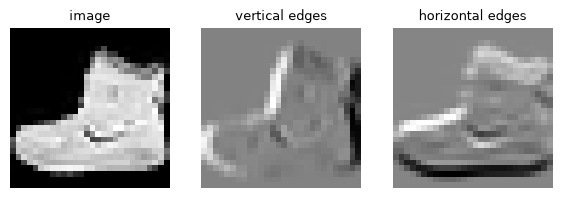

In [2]:
sobel = torch.tensor([[[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]],         # vertical edges
                      [[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]]]).unsqueeze(1)   # horizontal edges; shape (2, 1, 3, 3)
image = pixels[0:1]                                                                      # (1, 1, 28, 28), an ankle boot
edges = F.conv2d(image, sobel, padding=1)
print("image", tuple(image.shape), "* filters", tuple(sobel.shape), "->", tuple(edges.shape))

fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, img, title in zip(axes, [image[0, 0], edges[0, 0], edges[0, 1]], ["image", "vertical edges", "horizontal edges"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.show()

Output shapes and parameter counts for common settings, and a convolution compared with a dense layer on a full-size photo:

In [3]:
x = torch.randn(1, 3, 32, 32)
for k, s, p in [(3, 1, 0), (3, 1, 1), (3, 2, 1), (5, 1, 2), (1, 1, 0)]:
    conv = nn.Conv2d(3, 16, kernel_size=k, stride=s, padding=p)
    print(f"kernel {k}, stride {s}, padding {p}: {tuple(x.shape)} -> {tuple(conv(x).shape)}   "
          f"(32 + 2·{p} − {k}) // {s} + 1 = {(32 + 2 * p - k) // s + 1}   parameters {sum(q.numel() for q in conv.parameters())}")

dense = 224 * 224 * 3 * 64 + 64
conv = sum(q.numel() for q in nn.Conv2d(3, 64, kernel_size=3).parameters())
print(f"\n224x224 RGB photo -> 64 outputs:  dense layer {dense:,} parameters,  3x3 convolution with 64 filters {conv:,}")

kernel 3, stride 1, padding 0: (1, 3, 32, 32) -> (1, 16, 30, 30)   (32 + 2·0 − 3) // 1 + 1 = 30   parameters 448
kernel 3, stride 1, padding 1: (1, 3, 32, 32) -> (1, 16, 32, 32)   (32 + 2·1 − 3) // 1 + 1 = 32   parameters 448
kernel 3, stride 2, padding 1: (1, 3, 32, 32) -> (1, 16, 16, 16)   (32 + 2·1 − 3) // 2 + 1 = 16   parameters 448
kernel 5, stride 1, padding 2: (1, 3, 32, 32) -> (1, 16, 32, 32)   (32 + 2·2 − 5) // 1 + 1 = 32   parameters 1216
kernel 1, stride 1, padding 0: (1, 3, 32, 32) -> (1, 16, 32, 32)   (32 + 2·0 − 1) // 1 + 1 = 32   parameters 64

224x224 RGB photo -> 64 outputs:  dense layer 9,633,856 parameters,  3x3 convolution with 64 filters 1,792


Padding 1 keeps a 3×3 convolution's output at 32×32, and stride 2 halves it. The convolution needs about 5,400 times fewer parameters than the dense layer,
because its 64 small filters are reused at every position.

# 3. POOLING, RECEPTIVE FIELD AND 1×1 CONVOLUTIONS

- **Pooling** shrinks feature maps: **max pooling** keeps the largest value in each window (is the pattern present?), **average pooling** keeps the mean.
  A 2×2 window with stride 2 halves height and width. Many modern CNNs use stride-2 convolutions instead.
- **Global average pooling** averages each whole feature map into one number, so the classifier head needs far fewer weights (used by ResNet).
- **Receptive field:** the input area that one output value depends on. It grows with every layer: two 3×3 layers see 5×5, three see 7×7.
  Stacking small filters (VGG's idea) gives the same view as one big filter with fewer parameters and more non-linearities.
- **1×1 convolutions** mix channels at each position without looking at neighbours: a cheap way to change the number of channels (the "bottleneck" in ResNet and Inception).
- **Depthwise separable convolutions** (MobileNet) split a convolution into a per-channel spatial filter plus a 1×1 channel mix, with far fewer parameters.

In [4]:
count = lambda *layers: sum(p.numel() for layer in layers for p in layer.parameters())

print("max pooling 2x2:", F.max_pool2d(torch.arange(16.0).reshape(1, 1, 4, 4), 2).flatten().tolist(), "from a 4x4 grid of 0..15")
print(f"one 7x7 conv (64 -> 64 channels):   {count(nn.Conv2d(64, 64, 7)):,} parameters")
print(f"three 3x3 convs (same 7x7 view):    {count(*[nn.Conv2d(64, 64, 3) for _ in range(3)]):,} parameters")
print(f"3x3 conv, 64 -> 128 channels:       {count(nn.Conv2d(64, 128, 3)):,} parameters")
print(f"depthwise separable (3x3 + 1x1):    {count(nn.Conv2d(64, 64, 3, groups=64), nn.Conv2d(64, 128, 1)):,} parameters")

max pooling 2x2: [5.0, 7.0, 13.0, 15.0] from a 4x4 grid of 0..15
one 7x7 conv (64 -> 64 channels):   200,768 parameters
three 3x3 convs (same 7x7 view):    110,784 parameters
3x3 conv, 64 -> 128 channels:       73,856 parameters
depthwise separable (3x3 + 1x1):    8,960 parameters


Three stacked 3×3 layers see the same 7×7 area as one 7×7 layer with 55% of its parameters, and depthwise separable convolution needs about 12% of the parameters of a standard one.

# 4. A SMALL CNN ON FASHIONMNIST

Two convolution blocks (conv → BatchNorm → ReLU → max pool), then a small dense classifier. This is the classic pattern: the spatial size shrinks (28 → 14 → 7) while the number of channels grows (1 → 32 → 64).

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),    # 32 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),   # 64 x 7 x 7
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


model = SmallCNN()
print(f"parameters: convolution layers {count(model.features):,}, dense classifier {count(model.classifier):,}")


def ms_per_step(dev: torch.device, steps: int = 30) -> float:
    m = SmallCNN().to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    xb, yb = X_train[:128].to(dev), y_train[:128].to(dev)
    for i in range(steps + 3):
        if i == 3:
            synchronize(dev)
            start = time.perf_counter()
        opt.zero_grad()
        F.cross_entropy(m(xb), yb).backward()
        opt.step()
    synchronize(dev)
    return (time.perf_counter() - start) / steps * 1000


print(f"one training step, batch 128: cpu {ms_per_step(torch.device('cpu')):.1f} ms, {device.type} {ms_per_step(device):.1f} ms")

parameters: convolution layers 19,008, dense classifier 402,826


one training step, batch 128: cpu 38.1 ms, mps 4.2 ms


The two convolution layers have only 19,008 parameters; the dense classifier on top holds 402,826. That imbalance is why deeper CNNs end with global average pooling instead.

Here the GPU is 9x faster than the CPU per training step (4.2 ms against 38.1 ms). Convolutions do far more work per step than the small MLP in 02.2, where the CPU won.

In [6]:
def train(model: nn.Module, X_tr, y_tr, epochs: int, lr: float = 1e-3, batch: int = 128, params=None, keep_eval: bool = False,
          prepare=lambda x: x) -> list[float]:
    """Train on the GPU and return the validation accuracy after each epoch.
    keep_eval=True keeps the model in eval mode while training (for a frozen backbone, section 8)."""
    model = model.to(device)
    optimizer = torch.optim.AdamW(params if params is not None else model.parameters(), lr=lr)
    order = torch.Generator().manual_seed(0)
    history = []
    for _ in range(epochs):
        model.eval() if keep_eval else model.train()
        perm = torch.randperm(len(X_tr), generator=order)
        for i in range(len(X_tr) // batch):
            idx = perm[i * batch:(i + 1) * batch].to(device)
            optimizer.zero_grad()
            F.cross_entropy(model(prepare(X_tr[idx])), y_tr[idx]).backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            correct = sum((model(prepare(X_val[i:i + 500])).argmax(1) == y_val[i:i + 500]).sum().item() for i in range(0, len(X_val), 500))
        history.append(correct / len(X_val))
    return history


torch.manual_seed(0)
cnn = SmallCNN()
start = time.perf_counter()
history = train(cnn, X_train, y_train, epochs=5)
print("validation accuracy per epoch:", [round(a, 4) for a in history], f"({time.perf_counter() - start:.0f} s)")

validation accuracy per epoch: [0.8888, 0.901, 0.9022, 0.9105, 0.9103] (13 s)


The CNN reaches 0.889 after one epoch and 0.911 after five. The MLP in 02.2 needed 13 epochs to reach its best of 0.900. Keeping the 2D structure gives a better model in a fraction of the training.

# 5. WHAT THE FIRST LAYER SEES

The 32 feature maps of the first convolution layer for one test image, after training. Each filter has learned to respond to a different pattern: edges in some direction, bright areas, dark outlines.

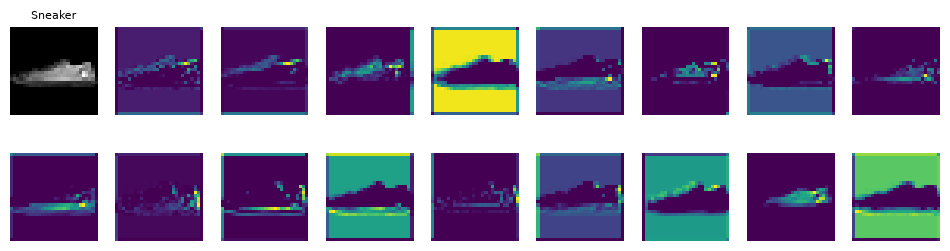

In [7]:
with torch.no_grad():
    maps = cnn.features[:3](X_val[:1])[0].cpu()          # conv -> BatchNorm -> ReLU for one image: (32, 28, 28)

fig, axes = plt.subplots(2, 9, figsize=(12, 3))
axes[0, 0].imshow(X_val[0, 0].cpu(), cmap="gray")
axes[0, 0].set_title(CLASSES[y_val[0]], fontsize=8)
for k, ax in enumerate(axes.flat[1:]):
    ax.imshow(maps[k], cmap="viridis")
for ax in axes.flat:
    ax.axis("off")
plt.show()

# 6. DATA AUGMENTATION

**Augmentation** creates new training images with random changes that keep the label: flips, small shifts, rotations, crops, colour changes.
The model learns that these changes don't matter, which reduces overfitting, especially with little data (03.2).
- Apply it to the **training data only**, freshly at random every epoch; validation and test images stay unchanged.
- Choose changes that keep the label: a mirrored shirt is still a shirt, but a mirrored "6" or a mirrored road sign may not be.
- Tools: `torchvision.transforms.v2`, Albumentations; automatic policies such as RandAugment; mixup and CutMix blend images and labels.

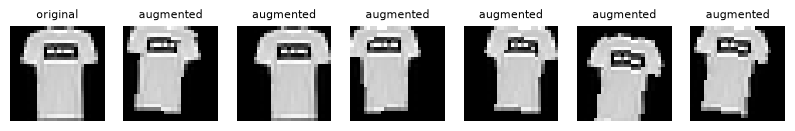

In [8]:
augment = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),   # small rotation, shift and zoom
])

torch.manual_seed(0)
fig, axes = plt.subplots(1, 7, figsize=(10, 1.8))
axes[0].imshow(images[1, 0], cmap="gray")
axes[0].set_title("original", fontsize=8)
for ax in axes[1:]:
    ax.imshow(augment(images[1])[0], cmap="gray")
    ax.set_title("augmented", fontsize=8)
for ax in axes:
    ax.axis("off")
plt.show()

# 7. CLASSIC ARCHITECTURES

| Model | Year | What it introduced |
|---|---|---|
| LeNet-5 | 1998 | conv → pool → dense, for digit recognition |
| AlexNet | 2012 | deep CNN on GPUs, ReLU, dropout; won ImageNet and started the deep learning boom |
| VGG | 2014 | only stacked 3×3 convolutions, very deep and simple |
| GoogLeNet (Inception) | 2014 | parallel branches with different filter sizes, 1×1 bottlenecks |
| **ResNet** | 2015 | residual connections (03.2); 50–152 layers; still a common backbone |
| MobileNet, EfficientNet | 2017–2019 | depthwise separable convolutions and balanced scaling, for phones and efficiency |
| Vision Transformer (ViT) | 2020 | splits the image into patches and uses attention (folder 06) instead of convolutions |
| ConvNeXt | 2022 | a CNN modernized with transformer-era design choices, competitive with ViTs |

Beyond classification, the same backbones power **object detection** (YOLO, Faster R-CNN, DETR), **segmentation** (U-Net, Mask R-CNN, SAM)
and the image encoders of vision-language models (folder 16).

# 8. TRANSFER LEARNING

Training a big CNN from scratch needs a lot of data. **Transfer learning** starts from a model pretrained on a large dataset (ImageNet: 1.2 million photos, 1,000 classes)
and adapts it. The early layers detect generic edges and textures that are useful for almost any image task.

| Strategy | What trains | When to use it |
|---|---|---|
| **feature extraction** | only a new head; the backbone is frozen | very little data, or a task close to the pretraining data; cheapest |
| **fine-tuning** | the whole network, with a small learning rate (about 10x lower) | more data, or a task that differs from the pretraining data |
| gradual unfreezing / layer-wise learning rates | the head first, then deeper layers, with smaller learning rates for early layers | a middle ground that reduces the risk of destroying pretrained features |

Two practical details: prepare the inputs **exactly as during pretraining** (3 channels, ImageNet mean and std, a similar resolution),
and when freezing a backbone with BatchNorm, keep it in **eval mode**. `requires_grad=False` stops the weights from changing, but in train mode BatchNorm still updates its running statistics.

The experiment: ResNet18 on only **2,000** FashionMNIST images (resized to 64×64 and copied to 3 channels), 10 epochs each, four ways.

In [9]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
raw = pixels.to(device)                                     # [0, 1] images, before FashionMNIST normalization
X_small, y_small = raw[:2000], y[:2000]
X_val = raw[54_000:]                                        # the validation images, prepared the same way below


def to_imagenet_input(x: torch.Tensor) -> torch.Tensor:
    """(n, 1, 28, 28) in [0, 1] -> (n, 3, 64, 64), normalized like ImageNet."""
    x = F.interpolate(x, size=64, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
    return (x - IMAGENET_MEAN) / IMAGENET_STD


pretrained = ResNet18_Weights.DEFAULT.get_state_dict(progress=False)      # about 45 MB, downloaded once


def resnet18(use_pretrained: bool) -> nn.Module:
    model = models.resnet18()
    if use_pretrained:
        model.load_state_dict(pretrained)
    model.fc = nn.Linear(model.fc.in_features, 10)          # a new head for 10 classes
    return model


print(f"ResNet18: {count(resnet18(False)):,} parameters, of which the new head has {count(nn.Linear(512, 10)):,}")
experiments = [   # name, pretrained weights, freeze the backbone, keep it in eval mode, learning rate
    ("from scratch", False, False, False, 1e-3),
    ("frozen backbone, BatchNorm in train mode", True, True, False, 1e-3),
    ("frozen backbone, kept in eval mode", True, True, True, 1e-3),
    ("fine-tune everything (lr 1e-4)", True, False, False, 1e-4),
]
for name, use_pretrained, freeze, keep_eval, lr in experiments:
    torch.manual_seed(0)
    model = resnet18(use_pretrained)
    params = None
    if freeze:
        for p in model.parameters():
            p.requires_grad_(False)
        for p in model.fc.parameters():
            p.requires_grad_(True)
        params = model.fc.parameters()
    start = time.perf_counter()
    acc = train(model, X_small, y_small, epochs=10, batch=64, lr=lr, params=params, keep_eval=keep_eval, prepare=to_imagenet_input)
    print(f"{name:<42} validation accuracy {acc[-1]:.4f}   ({time.perf_counter() - start:.0f} s)")

ResNet18: 11,181,642 parameters, of which the new head has 5,130


from scratch                               validation accuracy 0.8317   (21 s)


frozen backbone, BatchNorm in train mode   validation accuracy 0.7432   (12 s)


frozen backbone, kept in eval mode         validation accuracy 0.8303   (12 s)


fine-tune everything (lr 1e-4)             validation accuracy 0.8683   (20 s)


- **From scratch:** ResNet18's 11 million parameters reach 0.832 from only 2,000 images.
- **Frozen backbone, BatchNorm in train mode:** 0.743, the worst result. The running statistics drift towards the new data while the weights stay fixed.
- **The same frozen backbone, kept in eval mode:** 0.830. That's as good as training from scratch, while training only the 5,130-parameter head, in a little over half the time.
- **Fine-tuning everything:** clearly the best, 0.868, 3.7 points above training from scratch on the same 2,000 images.

Frozen features help less here than usual because 64×64 grayscale clothing photos look very different from ImageNet's colour photos. The closer a task is to the pretraining data, the better feature extraction works.

# 9. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Model for images | MLP / CNN / Vision Transformer | MLP: ignores the 2D layout. CNN: built-in locality, data-efficient, fast. ViT: scales better with huge data and pretraining, needs more data from scratch | a pretrained CNN or ViT; CNNs for small data and edge devices |
| Downsampling | max pooling / stride-2 convolution | pooling: no parameters, simple. Strided conv: learned, used by modern designs | either; strided convs in newer models |
| Classifier head | flatten + dense / global average pooling | flatten: keeps position detail, many parameters. GAP: tiny head, any input size | GAP for deep backbones, flatten for small CNNs like section 4 |
| Starting point | from scratch / pretrained | scratch: no assumptions, needs lots of data and compute. Pretrained: better with little data, converges faster, must match its preprocessing | pretrained almost always |
| How much to train | frozen backbone / fine-tune all | frozen: fast and cheap, weaker when the task differs from ImageNet. Fine-tuning: best accuracy, more compute and risk of overfitting tiny data | start frozen as a baseline, then fine-tune with a lower learning rate |
| Input resolution | small / large | small: fast, loses detail. Large: more accurate, cost grows with pixels | the pretraining resolution (224 for ResNet) when compute allows |
| Augmentation | none / light / heavy | none: overfits small data. Heavy: robust, slower to converge, can change labels if careless | light augmentation that keeps labels valid |

# 10. INTERVIEW QUESTIONS

### Q1. Why use CNNs instead of MLPs for images, in 30 seconds?
Convolutions use small filters that look at local patches and are shared across the whole image. That keeps the 2D structure, needs far fewer parameters,
and detects a pattern wherever it appears. Stacked layers build features from edges to objects, so CNNs learn images with much less data than MLPs.

### Q2. How do you compute a convolution's output size and parameter count?
Output = (input + 2·padding − kernel) / stride + 1, rounded down. Parameters = kernel × kernel × in_channels × out_channels + out_channels for the biases.
A 3×3 convolution from 64 to 128 channels has 73,856 parameters, whatever the image size.

### Q3. What do padding and stride do?
Padding adds zeros around the border so the output keeps its size and border pixels are used fully; 3×3 with padding 1 is "same" padding.
Stride is the step between filter positions; stride 2 halves the height and width.

### Q4. Max pooling vs average pooling? What is global average pooling?
Max pooling keeps the strongest response in each window ("is the feature here?"); average pooling keeps the mean. Global average pooling averages each whole feature map into one value,
replacing a large flattened dense layer and making the head small and size-independent.

### Q5. What is the receptive field, and why stack 3×3 convolutions?
The region of the input that one output depends on; it grows with depth. Three 3×3 layers cover 7×7 with about half the parameters of one 7×7 layer and add more non-linearities.

### Q6. What are 1×1 convolutions for?
They mix information across channels at each pixel, without looking at neighbours: a cheap way to reduce or increase the number of channels (bottlenecks in ResNet and Inception).

### Q7. What is a depthwise separable convolution?
A per-channel 3×3 spatial filter (depthwise) followed by a 1×1 convolution that mixes channels (pointwise). It needs several times fewer parameters and operations; MobileNet and EfficientNet are built on it.

### Q8. Translation equivariance vs invariance?
A convolution is equivariant: shift the input and the feature map shifts by the same amount. Pooling and global pooling make the final prediction approximately invariant: the class doesn't change when the object moves a little.

### Q9. Feature extraction or fine-tuning: when do you use each?
Feature extraction (frozen backbone, new head) for very little data or a task similar to the pretraining data: fast and hard to overfit.
Fine-tuning (all layers, about 10x lower learning rate) when there is more data or the domain differs; it adapts the features and usually scores higher (section 8).

### Q10. You froze a pretrained backbone with `requires_grad=False`, but its results are poor. What might be wrong?
BatchNorm layers still update their running statistics in train mode, so the "frozen" features keep shifting towards the new data's statistics.
Keep the backbone in `eval()` mode while training the head. In section 8 this alone moved accuracy from 0.743 to 0.830. Also check that the inputs use the pretraining normalization and channels.

### Q11. What data augmentation would you use for images, and what should you avoid?
Flips, small rotations and shifts, random crops and scaling, colour jitter, plus RandAugment, mixup or CutMix. Apply them only to training data, and avoid changes that alter the label
(flipping text or digits, colour changes when colour is the class).

### Q12. CNN vs Vision Transformer?
CNNs build in locality and translation equivariance, so they learn well from less data and run efficiently. ViTs split images into patches and use attention, with fewer built-in assumptions;
they need more data or pretraining but scale better and capture global context. With large-scale pretraining, both perform well.

### Q13. Why does a GPU speed up this CNN much more than the MLP from 02.2?
A convolution does many multiply-adds per value read from memory (every filter at every position), which is exactly the parallel work GPUs are built for.
The small MLP had too little work per step to hide the GPU's fixed costs.

# 11. IN MY OWN WORDS

Write this from memory, without looking above:

- Why convolutions beat dense layers for images:
- The output-size formula, and what padding and stride do:
- What pooling and 1×1 convolutions are for:
- Feature extraction vs fine-tuning, and the BatchNorm trap:
- Augmentations I'd use for a clothing classifier: